<a href="https://colab.research.google.com/github/roopeshscs24-maker/BIS-lab/blob/main/LungCancerGeneexpression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cancer samples: 58
Normal samples: 49

Gene Classification:
Status
Not Significant    1159
Downregulated       547
Upregulated         294
Name: count, dtype: int64

Top 10 Differentially Expressed Genes:


,Gene,Log2_FC,P_Value,Adjusted_P,Status
27,209074_s_at,-3.371799,6.641899e-44,1.328380e-40,Downregulated
178,204396_s_at,-2.388072,2.009124e-41,2.009124e-38,Downregulated
104,204677_at,-2.619573,1.317136e-40,8.780905e-38,Downregulated
520,208982_at,-1.813914,3.357325e-39,1.678662e-36,Downregulated
1871,213103_at,-1.219820,5.221337e-39,2.088535e-36,Downregulated
654,208981_at,-1.688902,7.219182e-39,2.406394e-36,Downregulated
3,210081_at,-4.417470,4.769095e-38,1.362599e-35,Downregulated
1342,219719_at,-1.363973,1.714932e-37,3.565064e-35,Downregulated
217,202112_at,-2.258474,1.464679e-37,3.565064e-35,Downregulated
4,209875_s_at,4.364415,1.782532e-37,3.565064e-35,Upregulated


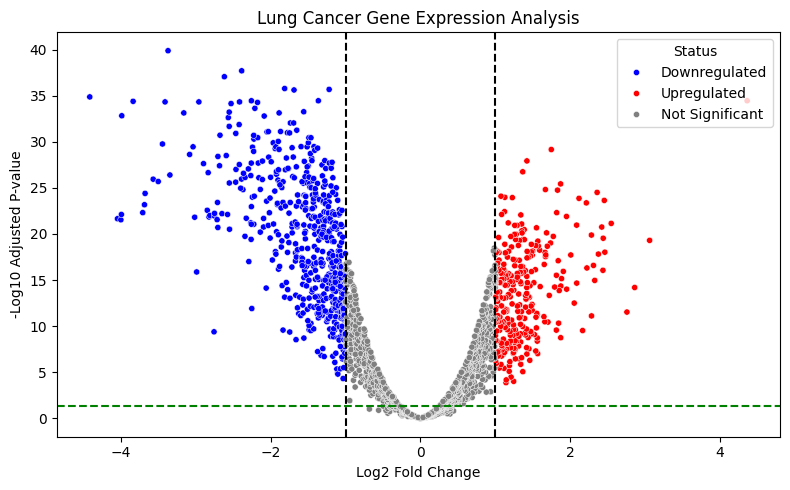


Analysis Completed Successfully!
Results saved as Lung_Cancer_Results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# LUNG CANCER GENE EXPRESSION ANALYSIS

!pip install GEOparse -q

import GEOparse
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

# 1. Download dataset
print("Downloading dataset...")

gse = GEOparse.get_GEO(
    "GSE10072",
    destdir="./",
    silent=True
)

# 2. Extract expression data
samples = {}

for sid, gsm in gse.gsms.items():
    table = gsm.table
    if "ID_REF" in table.columns and "VALUE" in table.columns:
        samples[sid] = table.set_index("ID_REF")["VALUE"]

data = pd.DataFrame(samples).apply(
    pd.to_numeric, errors="coerce"
)

# 3. Identify sample groups
groups = {}

for sid, gsm in gse.gsms.items():
    info = " ".join(
        gsm.metadata.get("title", []) +
        gsm.metadata.get("source_name_ch1", []) +
        gsm.metadata.get("characteristics_ch1", [])
    ).lower()

    if any(x in info for x in ["normal", "non-tumor", "non tumor", "control"]):
        groups[sid] = "Normal"
    elif any(x in info for x in ["tumor", "tumour", "cancer", "adenocarcinoma"]):
        groups[sid] = "Cancer"

groups = pd.Series(groups)
groups = groups[groups.index.isin(data.columns)]
data = data[groups.index]

if len(groups[groups == "Cancer"]) < 2 or len(groups[groups == "Normal"]) < 2:
    raise ValueError("Sample groups could not be identified correctly.")

print("Cancer samples:", sum(groups == "Cancer"))
print("Normal samples:", sum(groups == "Normal"))

# 4. Preprocessing
data = data.dropna(thresh=int(0.8 * data.shape[1]))
data = data.T.fillna(data.median(axis=1)).T
data = data.loc[data.var(axis=1) > 0]

# Select top 2000 variable genes
data = data.loc[
    data.var(axis=1).nlargest(min(2000, len(data))).index
]

# 5. Separate groups
cancer = data[groups[groups == "Cancer"].index].values
normal = data[groups[groups == "Normal"].index].values

# 6. Statistical analysis
logfc = cancer.mean(axis=1) - normal.mean(axis=1)

_, pvalues = ttest_ind(
    cancer, normal,
    axis=1,
    equal_var=False,
    nan_policy="omit"
)

pvalues = np.nan_to_num(pvalues, nan=1.0)

adjusted = multipletests(
    pvalues,
    method="fdr_bh"
)[1]

# 7. Gene classification
result = pd.DataFrame({
    "Gene": data.index,
    "Log2_FC": logfc,
    "P_Value": pvalues,
    "Adjusted_P": adjusted
})

result["Status"] = "Not Significant"

result.loc[
    (result.Adjusted_P < 0.05) & (result.Log2_FC > 1),
    "Status"
] = "Upregulated"

result.loc[
    (result.Adjusted_P < 0.05) & (result.Log2_FC < -1),
    "Status"
] = "Downregulated"

# 8. Display results
print("\nGene Classification:")
print(result["Status"].value_counts())

print("\nTop 10 Differentially Expressed Genes:")
display(result.sort_values("Adjusted_P").head(10))

# 9. Volcano plot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=result,
    x="Log2_FC",
    y=-np.log10(result["Adjusted_P"].clip(lower=1e-300)),
    hue="Status",
    palette={
        "Upregulated": "red",
        "Downregulated": "blue",
        "Not Significant": "gray"
    },
    s=20
)

plt.axvline(1, color="black", linestyle="--")
plt.axvline(-1, color="black", linestyle="--")
plt.axhline(-np.log10(0.05), color="green", linestyle="--")

plt.title("Lung Cancer Gene Expression Analysis")
plt.xlabel("Log2 Fold Change")
plt.ylabel("-Log10 Adjusted P-value")
plt.tight_layout()
plt.show()

# 10. Save results
result.to_csv("Lung_Cancer_Results.csv", index=False)

print("\nAnalysis Completed Successfully!")
print("Results saved as Lung_Cancer_Results.csv")

from google.colab import files
files.download("Lung_Cancer_Results.csv")
